In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("cs1090a_hw5.ipynb")

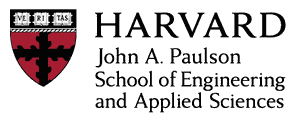

# CS1090A Introduction to Data Science
## Homework 5: Which students will finish their degree?
### Decision trees & ensembles

**Harvard University**<br/>
**Fall 2026**<br/>
**Instructors**: Pavlos Protopapas, Kevin Rader, and Chris Gumb

<hr style="height:2.4pt">

## Instructions

This assignment is graded out of 70 points, for CS1090A and AC209A students alike.

This assignment is open-ended. You build two classifiers for the same problem: a single decision tree in Part 2 and an ensemble of your choice in Part 3. Each question names a decision, such as how to prepare the data, how to choose and tune the model, or how to interpret it, and you make that decision yourself. There is usually more than one defensible choice. You are graded on whether each choice is justified with evidence from your own output, not on whether it matches the staff's choice. Add code and markdown cells as you need them, and answer each written response in a short paragraph.

**Running the notebook**

- Your submitted notebook must run in order after restarting the kernel, using only the files in this bundle, in under 35 minutes. The last cell prints the runtime.
- Re-running your notebook must reproduce your submission files exactly, so set `random_state` wherever randomness enters.

**Kaggle**

Each model has a Kaggle competition, scored by macro-F1 (defined in Part 1). Each Kaggle question (Q2.4 and Q3.4) is worth 5 points, pass/fail: you receive them if you submitted, if re-running your notebook reproduces the file you upload to Gradescope, and if your score beats the floor benchmark shown on the leaderboard. Your rank does not affect your grade. The competitions' Overview and Rules pages give the details. The four students ranked highest on the ensemble competition's private leaderboard win a dinner with Kevin, Pavlos, and Chris.

**What to upload to Gradescope:** the notebook and the two files `submission_dt.csv` and `submission_ensemble.csv` from your `submissions/` folder, as three separate files (not a zip).

**Use of AI tools**

You may use AI tools. You are accountable for everything you submit: you must understand it and be able to explain it.

- Written answers must be your own words.
- Quizzes and midterms ask you to explain and apply these methods.

All plots must have axis labels, a descriptive title, and a legend when colors, symbols, or reference lines distinguish information.

In [2]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

notebook_start = time.time()

# Setup. The data and a supplied function

The data come from a public dataset of 4,424 students at the Polytechnic Institute of Portalegre, Portugal, described in the paper by Martins et al. in `data/early_prediction_of_students_performance.pdf`. Each row is one student, and the 21 columns describe the student at the time they enrolled. The outcome is one of three classes: the student dropped out (`Dropout`), was still enrolled at the end of the program's normal duration (`Enrolled`), or graduated (`Graduate`).

The staff have already removed the columns that would not be known at enrollment, such as first-semester grades. Those columns describe what happened after enrollment, so a model that used them would not be predicting at enrollment at all. Removing a column like this prevents **data leakage**.

You have the outcomes for the 3,318 training rows. The 1,106 rows in `X_test.csv` have no outcomes; the Kaggle competitions score your predictions for them. Because you never see the test outcomes, **every number you report in this notebook comes from the training rows**. How you estimate a model's performance on students it has not seen is one of your decisions.

<details><summary><b>Column descriptions</b> (click to expand)</summary>

| Column | Description |
|---|---|
| `Marital status` | 1 single, 2 married, 3 widower, 4 divorced, 5 facto union, 6 legally separated |
| `Application mode` | how the student applied: 1 1st phase, general contingent; 2 Ordinance No. 612/93; 5 1st phase, special contingent (Azores); 7 holders of other higher courses; 10 Ordinance No. 854-B/99; 15 international student (bachelor); 16 1st phase, special contingent (Madeira); 17 2nd phase, general contingent; 18 3rd phase, general contingent; 26 Ordinance No. 533-A/99 (different plan); 27 Ordinance No. 533-A/99 (other institution); 39 over 23 years old; 42 transfer; 43 change of course; 44 technological specialization diploma holders; 51 change of institution/course; 53 short cycle diploma holders; 57 change of institution/course (international) |
| `Application order` | the rank of this program among the student's choices, from 0 (first choice) to 9 (last choice) |
| `Course` | the degree program: 33 Biofuel Production Technologies, 171 Animation and Multimedia Design, 8014 Social Service (evening), 9003 Agronomy, 9070 Communication Design, 9085 Veterinary Nursing, 9119 Informatics Engineering, 9130 Equinculture, 9147 Management, 9238 Social Service, 9254 Tourism, 9500 Nursing, 9556 Oral Hygiene, 9670 Advertising and Marketing Management, 9773 Journalism and Communication, 9853 Basic Education, 9991 Management (evening) |
| `Daytime/evening attendance` | 1 daytime, 0 evening |
| `Previous qualification` | type of the student's previous qualification (codes for levels of secondary schooling, higher-education degrees and technical programs; see the paper) |
| `Previous qualification (grade)` | grade of the previous qualification, on a 0 to 200 scale |
| `Nationality` | coded nationality, for example 1 Portuguese, 6 Spanish, 41 Brazilian, 62 Romanian |
| `Mother's qualification`, `Father's qualification` | each parent's education (codes for levels of schooling and degrees) |
| `Mother's occupation`, `Father's occupation` | each parent's occupation category (codes for groups such as specialists, technicians, administrative staff, service workers, skilled and unskilled workers) |
| `Admission grade` | the student's admission grade, on a 0 to 200 scale |
| `Displaced` | 1 if the student moved to attend the institution, 0 if not |
| `Educational special needs` | 1 yes, 0 no |
| `Debtor` | 1 if the student owed money to the institution, 0 if not |
| `Tuition fees up to date` | 1 yes, 0 no |
| `Gender` | 1 male, 0 female |
| `Scholarship holder` | 1 yes, 0 no |
| `Age at enrollment` | the student's age in years when they enrolled |
| `International` | 1 yes, 0 no |
| `Target` (in `y_train.csv`) | the outcome at the end of the program's normal duration: `Dropout`, `Enrolled` (still enrolled, not yet graduated) or `Graduate` |

</details>

In [3]:
# Supplied: the data and the function that writes Kaggle submission files. Do not change this cell.
X_train = pd.read_csv("data/X_train.csv")
y_train = pd.read_csv("data/y_train.csv")["Target"]
X_test = pd.read_csv("data/X_test.csv")

CLASSES = ["Dropout", "Enrolled", "Graduate"]
os.makedirs("submissions", exist_ok=True)


def write_submission(predictions, kind):
    """Write one Kaggle submission file. `kind` is "dt" or "ensemble"."""
    column = {"dt": "DT_Predicted", "ensemble": "Ensemble_Predicted"}[kind]
    assert len(predictions) == len(X_test), "predict X_test, all 1,106 rows, in their original order"
    path = f"submissions/submission_{kind}.csv"
    pd.DataFrame({"ID": X_test.index, column: predictions}).to_csv(path, index=False)
    print(f"wrote {path}: {len(predictions)} rows,", pd.Series(predictions).value_counts().to_dict())


print(f"{len(X_train):,} training rows, {len(X_test):,} test rows, {X_train.shape[1]} columns")

3,318 training rows, 1,106 test rows, 21 columns


In [4]:
# Our setup: the scikit-learn pieces we use, one seed for every source of randomness, and the column groups.
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 209
NOMINAL = ["Marital status", "Application mode", "Course", "Previous qualification", "Nationality",
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARY = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
          "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
NUMERIC = ["Application order", "Previous qualification (grade)", "Admission grade", "Age at enrollment"]
assert sorted(NOMINAL + BINARY + NUMERIC) == sorted(X_train.columns)
pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
plt.rcParams["font.size"] = 11

# Part 1. The data and the leaderboard metric

**Precision** for a class is the share of students predicted to be in that class who really are in it, and **recall** for a class is the share of students in that class whom the model predicts to be in it. The **F1 score** for a class combines the two as $2 \cdot \text{precision} \cdot \text{recall} / (\text{precision} + \text{recall})$, which is high only when both are high. **Macro-F1** is the average of the three classes' F1 scores, with each class counted equally however many students it has. Both Kaggle competitions score macro-F1.

## Q1.1. Explore the data

**5 points**

Explore the training data in whatever way you judge most useful for the modeling in Parts 2 and 3. In the written response, summarize what you found and how it will shape your modeling decisions.

,students,share
Target,,
Dropout,1066,0.321
Enrolled,595,0.179
Graduate,1657,0.499


Target,n,Dropout,Enrolled,Graduate
Tuition fees up to date = 0,397,0.866,0.081,0.053
Tuition fees up to date = 1,2921,0.247,0.193,0.560
Debtor = 0,2944,0.279,0.181,0.540
Debtor = 1,374,0.655,0.166,0.179
Scholarship holder = 0,2483,0.388,0.200,0.412
Scholarship holder = 1,835,0.122,0.119,0.759
Gender = 0,2154,0.252,0.170,0.578
Gender = 1,1164,0.449,0.197,0.354


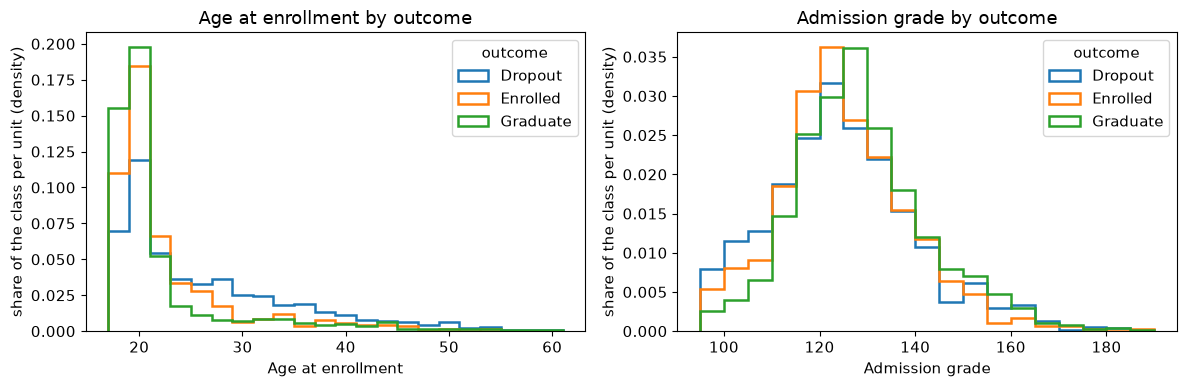

,Age at enrollment,Admission grade
Target,,
Dropout,23.000,123.374
Enrolled,20.000,123.663
Graduate,19.000,127.350


,levels,levels with < 30 students,X_test rows with a code not in training
Marital status,6,3,0
Application mode,18,9,0
Course,17,1,0
Previous qualification,16,10,1
Nationality,18,17,4
Mother's qualification,27,18,2
Father's qualification,30,22,4
Mother's occupation,31,21,1
Father's occupation,41,29,5


dropout share by course, lowest and highest three:


,n,dropout share
Course,,
9500,568,0.146
9238,270,0.185
9070,167,0.222
9119,126,0.532
9130,110,0.573
33,10,0.700


missing values: 0 in training, 0 in test; duplicated training rows: 0; X_test rows with any unseen code: 16
International == (Nationality != 1) on 3318 of 3318 rows
Courses of the evening students: [8014, 9991] | evening share in those courses: 1.0
youngest student who applied through mode 39 (over 23 years old): 24


In [5]:
# Q1.1: class balance, the columns that separate the classes, and what the coded columns look like.
counts = y_train.value_counts().reindex(CLASSES)
display(pd.DataFrame({"students": counts, "share": (counts / len(y_train)).round(3)}))


def outcome_shares(col):
    """Outcome shares within each value of a column, with the number of students."""
    table = pd.crosstab(X_train[col], y_train, normalize="index")[CLASSES].round(3)
    table.insert(0, "n", X_train[col].value_counts().sort_index())
    table.index = [f"{col} = {v}" for v in table.index]
    return table


display(pd.concat([outcome_shares(c) for c in ["Tuition fees up to date", "Debtor", "Scholarship holder", "Gender"]]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, bins in zip(axes, ["Age at enrollment", "Admission grade"], [np.arange(17, 63, 2), np.arange(95, 191, 5)]):
    for cls in CLASSES:
        ax.hist(X_train.loc[y_train == cls, col], bins=bins, density=True, histtype="step", linewidth=1.8, label=cls)
    ax.set(xlabel=col, ylabel="share of the class per unit (density)", title=f"{col} by outcome")
    ax.legend(title="outcome")
plt.tight_layout()
plt.show()
display(X_train.groupby(y_train)[["Age at enrollment", "Admission grade"]].median().reindex(CLASSES))

codes = pd.DataFrame({
    "levels": X_train[NOMINAL].nunique(),
    "levels with < 30 students": [(X_train[c].value_counts() < 30).sum() for c in NOMINAL],
    "X_test rows with a code not in training": [(~X_test[c].isin(X_train[c])).sum() for c in NOMINAL]})
display(codes)
by_course = pd.DataFrame({"n": X_train["Course"].value_counts(),
                          "dropout share": pd.crosstab(X_train["Course"], y_train, normalize="index")["Dropout"]})
print("dropout share by course, lowest and highest three:")
display(by_course.sort_values("dropout share").iloc[[0, 1, 2, -3, -2, -1]])
unseen_rows = (~X_test[NOMINAL].apply(lambda col: col.isin(X_train[col.name]))).any(axis=1)
print(f"missing values: {X_train.isna().sum().sum()} in training, {X_test.isna().sum().sum()} in test; "
      f"duplicated training rows: {X_train.duplicated().sum()}; X_test rows with any unseen code: {unseen_rows.sum()}")

# Columns that repeat information another column already carries.
print("International == (Nationality != 1) on",
      ((X_train["International"] == 1) == (X_train["Nationality"] != 1)).sum(), "of", len(X_train), "rows")
print("Courses of the evening students:",
      sorted(X_train.loc[X_train["Daytime/evening attendance"] == 0, "Course"].unique().tolist()),
      "| evening share in those courses:",
      (X_train.loc[X_train["Course"].isin([8014, 9991]), "Daytime/evening attendance"] == 0).mean())
print("youngest student who applied through mode 39 (over 23 years old):",
      X_train.loc[X_train["Application mode"] == 39, "Age at enrollment"].min())

**Written response: Q1.1**

- Enrolled is only 17.9% of the 3,318 students (Graduate 49.9%, Dropout 32.1%), but macro-F1 gives it a third of the score. So both models get class weights, and we check what the weights do.
- Money and scholarships separate the classes most. Of the 397 students behind on tuition, 86.6% dropped out (24.7% of the rest). Debtors dropped out 65.5% of the time, and scholarship holders graduated 75.9% of the time (41.2% without one). Dropouts are older (median 23 vs 19 for graduates) and more often male (44.9% of men vs 25.2% of women), while admission grades barely differ. The dropout share by program runs from 0.146 (Nursing, 568 students) to 0.573 (course 9130, 110 students).
- Nothing is missing or duplicated, so nothing needs imputing. Nine columns are unordered codes with many rare levels (29 of the 41 father's occupation codes have under 30 students), and 16 test rows have a code never seen in training, so the encoding is a real choice (Q2.1). Some columns copy others. International equals "Nationality is not 1" on all 3,318 rows, evening attendance happens only in courses 8014 and 9991, and nobody in application mode 39 (over 23) is younger than 24. Copies split importance between them, which matters when we interpret the models.

## Q1.2. Establish a baseline

**3 points**

Before building models, decide what a model has to beat to be useful on this problem. Compute that baseline and, in the written response, explain why it is the right point of comparison.

In [6]:
# Q1.2: the split behind every estimate in this notebook, and three rules that use no model.
X_dev, X_hold, y_dev, y_hold = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                                random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"development rows {len(X_dev):,}, holdout rows {len(X_hold):,}")


def fee_rule(X):
    """Dropout if the student is behind on tuition or owes the institution money, else Graduate."""
    return np.where((X["Tuition fees up to date"] == 0) | (X["Debtor"] == 1), "Dropout", "Graduate")


baselines = {}
for name, dummy in {"always Graduate (majority class)": DummyClassifier(strategy="most_frequent"),
                    "guess in proportion to class shares": DummyClassifier(strategy="stratified", random_state=SEED)}.items():
    pred = dummy.fit(X_dev, y_dev).predict(X_hold)
    baselines[name] = {"CV macro-F1": cross_val_score(dummy, X_dev, y_dev, cv=cv, scoring="f1_macro").mean(),
                       "holdout macro-F1": f1_score(y_hold, pred, average="macro"),
                       "holdout accuracy": np.mean(pred == y_hold)}
fold_rule_cv = [f1_score(y_dev.iloc[val], fee_rule(X_dev.iloc[val]), average="macro") for _, val in cv.split(X_dev, y_dev)]
baselines["fee rule: behind on fees or debtor -> Dropout"] = {
    "CV macro-F1": np.mean(fold_rule_cv), "holdout macro-F1": f1_score(y_hold, fee_rule(X_hold), average="macro"),
    "holdout accuracy": np.mean(fee_rule(X_hold) == y_hold)}
baseline_table = pd.DataFrame.from_dict(baselines, orient="index")
display(baseline_table.round(3))
print("expected macro-F1 of guessing in proportion to the class shares: 1/3 = 0.333 "
      "(each class's precision and recall both equal its share)")
rule_f1 = f1_score(y_hold, fee_rule(X_hold), average=None, labels=CLASSES, zero_division=0)
print("fee rule, holdout F1 by class:", dict(zip(CLASSES, rule_f1.round(3).tolist())))

development rows 2,654, holdout rows 664


,CV macro-F1,holdout macro-F1,holdout accuracy
always Graduate (majority class),0.222,0.222,0.500
guess in proportion to class shares,0.326,0.349,0.410
fee rule: behind on fees or debtor -> Dropout,0.411,0.402,0.596


expected macro-F1 of guessing in proportion to the class shares: 1/3 = 0.333 (each class's precision and recall both equal its share)
fee rule, holdout F1 by class: {'Dropout': 0.492, 'Enrolled': 0.0, 'Graduate': 0.713}


**Written response: Q1.2**

- Always predicting Graduate gets 0.500 accuracy but only 0.222 macro-F1, because the other two classes score 0. That is why accuracy is the wrong yardstick here. Guessing in proportion to the class shares has an expected macro-F1 of exactly 1/3, since each class's precision and recall both equal its share. Our one draw got 0.349 on the holdout.
- Our bar is a rule a registrar could apply without a model: Dropout if the student is behind on fees or in debt, otherwise Graduate. It scores 0.402 on the holdout and 0.411 in CV. A model that can't beat two columns and an if-statement isn't worth fitting. The rule never predicts Enrolled (F1 0.0), so beating it means catching some of those students. All baselines are scored on the same folds and holdout as the models, so the numbers compare directly.

# Part 2. Model 1: a single decision tree

Your first model is a single decision tree.

## Q2.1. Prepare the data

**5 points**

Prepare the data for your decision tree. In the written response, explain each preprocessing decision you made, including any decision to leave something unchanged, and why it suits a decision tree.

In [7]:
# Q2.1: drop the one column that repeats another, and compare two ways of giving the coded columns to a tree.
KEPT = [c for c in X_train.columns if c != "International"]   # International == (Nationality != 1) on every row
OTHER = [c for c in KEPT if c not in NOMINAL]
raw_codes = make_column_transformer(("passthrough", KEPT), verbose_feature_names_out=False)
one_hot = make_column_transformer(
    (OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist", sparse_output=False), NOMINAL),
    ("passthrough", OTHER), verbose_feature_names_out=False)
print("columns after each encoding:", raw_codes.fit(X_dev).transform(X_dev).shape[1], "raw codes,",
      one_hot.fit(X_dev).transform(X_dev).shape[1], "one-hot (codes with < 30 students pooled per column)")

encoding_cv = {}
for name, prep in {"raw codes": raw_codes, "one-hot": one_hot}.items():
    for depth in [3, 5, 7, 10]:
        pipe = Pipeline([("prep", prep), ("tree", DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20,
                                                                          class_weight="balanced", random_state=SEED))])
        scores = cross_val_score(pipe, X_dev, y_dev, cv=cv, scoring="f1_macro")
        encoding_cv[(name, depth)] = f"{scores.mean():.3f} ({scores.std():.3f})"
display(pd.Series(encoding_cv).unstack(0).rename_axis("max_depth (min_samples_leaf 20, balanced weights)"))

columns after each encoding: 20 raw codes, 90 one-hot (codes with < 30 students pooled per column)


,one-hot,raw codes
"max_depth (min_samples_leaf 20, balanced weights)",,
3,0.487 (0.020),0.487 (0.020)
5,0.508 (0.019),0.493 (0.026)
7,0.502 (0.031),0.515 (0.014)
10,0.501 (0.022),0.511 (0.026)


**Written response: Q2.1**

- The numeric and 0/1 columns stay as they are. A tree only compares a value with a threshold, so scaling or any other order-preserving change gives the same splits, and outliers can't drag a split around. Nothing is missing, so there is nothing to impute.
- We dropped International. It equals "Nationality is not 1" on every row and would only share credit with Nationality. We kept evening attendance and application mode even though they overlap with course and age, because one flag is easier to read than a pair of course columns.
- The nine code columns are categories, so a threshold on a code number groups programs that just happen to have nearby codes. We compared raw codes with one-hot columns, pooling codes held by under 30 students into one "infrequent" column per variable (90 columns). The two were within one fold SD at every depth (0.508 vs 0.493 at depth 5, 0.502 vs 0.515 at depth 7). With no real difference in performance, we chose one-hot. Its splits read as "Course is Nursing", and the 16 test rows with unseen codes land in the infrequent column. The encoder is fit inside each CV fold.

## Q2.2. Choose and tune your tree

**8 points**

Select your final decision tree. In the written response, explain what you tuned and why, how you estimated performance on students the model has not seen, and the evidence that led to your final choice.

,depth,leaf,weights,mean_test_score,std_test_score,mean_train_score
149,8,80,balanced,0.527,0.018,0.556
173,11,80,balanced,0.527,0.018,0.559
165,10,80,balanced,0.527,0.018,0.559
189,None,80,balanced,0.527,0.018,0.559
181,12,80,balanced,0.527,0.018,0.559
157,9,80,balanced,0.525,0.019,0.557
117,4,80,balanced,0.524,0.014,0.532
133,6,80,balanced,0.524,0.019,0.543


best of 192 settings: 0.527 (fold SD 0.018, SE 0.008) at depth 8, leaf 80, balanced
chosen by the one-SE rule: depth 4, leaf 80, balanced, CV macro-F1 0.524 (fold SD 0.014), training macro-F1 0.532


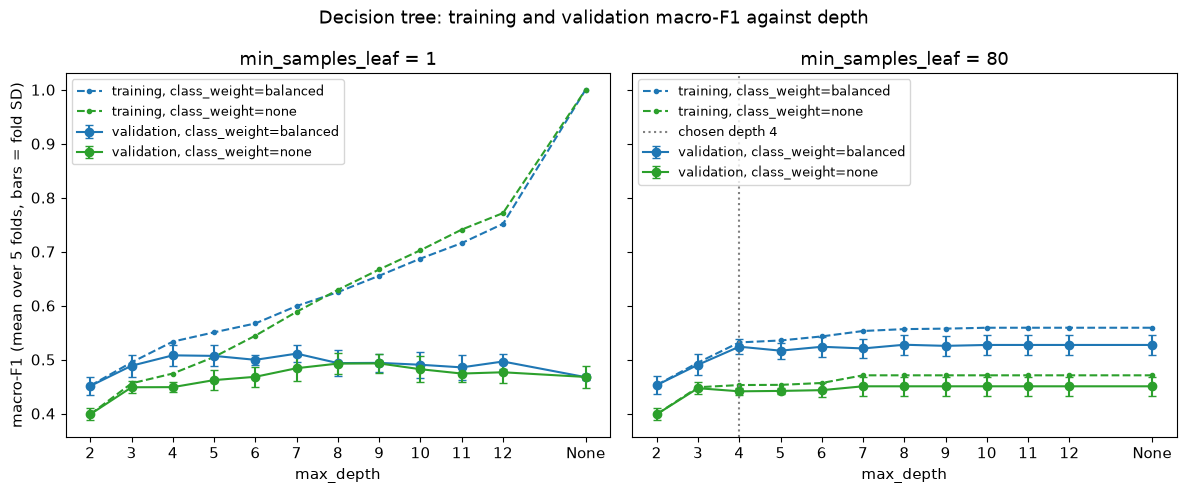

leaf 1, balanced, unlimited depth: training 1.000, validation 0.467
class_weight=None: out-of-fold F1 Dropout 0.600, Enrolled 0.000, Graduate 0.724; predicted Enrolled for 0.0% of students


class_weight=balanced: out-of-fold F1 Dropout 0.610, Enrolled 0.344, Graduate 0.620; predicted Enrolled for 38.7% of students
holdout macro-F1 0.480
              precision    recall  f1-score   support

     Dropout      0.646     0.488     0.556       213
    Enrolled      0.226     0.605     0.329       119
    Graduate      0.777     0.431     0.554       332

    accuracy                          0.480       664
   macro avg      0.550     0.508     0.480       664
weighted avg      0.636     0.480     0.514       664



In [8]:
# Q2.2: tune depth, leaf size and class weights on the five folds; keep the simplest tree within one SE of the best.
tree_pipe = Pipeline([("prep", one_hot), ("tree", DecisionTreeClassifier(criterion="gini", random_state=SEED))])
tree_grid = {"tree__max_depth": list(range(2, 13)) + [None],
             "tree__min_samples_leaf": [1, 5, 10, 20, 40, 80, 120, 160],
             "tree__class_weight": [None, "balanced"]}


def cv_table(cv_results):
    """cv_results_ as a DataFrame with plain columns; an unlimited depth is shown as inf."""
    res = pd.DataFrame(cv_results)
    res["depth"] = pd.to_numeric(res["param_tree__max_depth"], errors="coerce").fillna(np.inf)
    res["leaf"] = res["param_tree__min_samples_leaf"].astype(int)
    res["weights"] = res["param_tree__class_weight"].fillna("none").astype(str)
    return res


def one_se_rule(cv_results):
    """Shallowest tree (then largest leaf) whose mean CV macro-F1 is within one SE of the best mean."""
    res = cv_table(cv_results)
    best = res["mean_test_score"].idxmax()
    floor = res.loc[best, "mean_test_score"] - res.loc[best, "std_test_score"] / np.sqrt(cv.get_n_splits())
    return res[res["mean_test_score"] >= floor].sort_values(["depth", "leaf"], ascending=[True, False]).index[0]


tree_search = GridSearchCV(tree_pipe, tree_grid, scoring="f1_macro", cv=cv, refit=one_se_rule,
                           return_train_score=True, n_jobs=-1).fit(X_dev, y_dev)
tree_res = cv_table(tree_search.cv_results_)
best_row = tree_res.loc[tree_res["mean_test_score"].idxmax()]
chosen_row = tree_res.loc[tree_search.best_index_]
cols = ["depth", "leaf", "weights", "mean_test_score", "std_test_score", "mean_train_score"]
display(tree_res.sort_values("mean_test_score", ascending=False)[cols].head(8)
        .assign(depth=lambda d: d["depth"].map(lambda v: "None" if np.isinf(v) else int(v))))
print(f"best of {len(tree_res)} settings: {best_row['mean_test_score']:.3f} (fold SD {best_row['std_test_score']:.3f}, "
      f"SE {best_row['std_test_score'] / np.sqrt(5):.3f}) at depth {best_row['depth']:g}, leaf {best_row['leaf']}, {best_row['weights']}")
print(f"chosen by the one-SE rule: depth {chosen_row['depth']:g}, leaf {chosen_row['leaf']}, {chosen_row['weights']}, "
      f"CV macro-F1 {chosen_row['mean_test_score']:.3f} (fold SD {chosen_row['std_test_score']:.3f}), "
      f"training macro-F1 {chosen_row['mean_train_score']:.3f}")

# Validation and training curves against depth: unlimited leaves (left) and the chosen leaf size (right).
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, leaf in zip(axes, [1, chosen_row["leaf"]]):
    for weights, color in [("balanced", "tab:blue"), ("none", "tab:green")]:
        rows = tree_res[(tree_res["leaf"] == leaf) & (tree_res["weights"] == weights)].sort_values("depth")
        x = rows["depth"].replace(np.inf, 14)
        ax.errorbar(x, rows["mean_test_score"], yerr=rows["std_test_score"], color=color, marker="o", capsize=3,
                    label=f"validation, class_weight={weights}")
        ax.plot(x, rows["mean_train_score"], color=color, linestyle="--", marker=".", label=f"training, class_weight={weights}")
    if leaf == chosen_row["leaf"]:
        ax.axvline(chosen_row["depth"], color="grey", linestyle=":", label=f"chosen depth {chosen_row['depth']:g}")
    ax.set_xticks(list(range(2, 13)) + [14], [str(d) for d in range(2, 13)] + ["None"])
    ax.set(xlabel="max_depth", title=f"min_samples_leaf = {leaf}")
    ax.legend(fontsize=9, loc="upper left")
axes[0].set_ylabel("macro-F1 (mean over 5 folds, bars = fold SD)")
fig.suptitle("Decision tree: training and validation macro-F1 against depth")
plt.tight_layout()
plt.show()
print("leaf 1, balanced, unlimited depth: training", f"{tree_res.query('leaf == 1 and weights == \"balanced\" and depth == inf')['mean_train_score'].iloc[0]:.3f},",
      "validation", f"{tree_res.query('leaf == 1 and weights == \"balanced\" and depth == inf')['mean_test_score'].iloc[0]:.3f}")

# What class weights do to the Enrolled class at the chosen depth and leaf size.
for weights in [None, "balanced"]:
    pred = cross_val_predict(clone(tree_search.best_estimator_).set_params(tree__class_weight=weights), X_dev, y_dev, cv=cv)
    f1s = f1_score(y_dev, pred, average=None, labels=CLASSES)
    print(f"class_weight={weights}: out-of-fold F1 Dropout {f1s[0]:.3f}, Enrolled {f1s[1]:.3f}, Graduate {f1s[2]:.3f}; "
          f"predicted Enrolled for {np.mean(pred == 'Enrolled'):.1%} of students")

# The estimate for students the model has not seen: the chosen tree, fit on the development rows, on the holdout.
dt_dev = tree_search.best_estimator_
dt_hold_pred = dt_dev.predict(X_hold)
print(f"holdout macro-F1 {f1_score(y_hold, dt_hold_pred, average='macro'):.3f}")
print(classification_report(y_hold, dt_hold_pred, digits=3))

# The tree we submit: the same settings, refit on all 3,318 training rows.
dt_final = clone(dt_dev).fit(X_train, y_train)

**Written response: Q2.2**

- We tuned max_depth (2 to 12, or unlimited) and min_samples_leaf (1 to 160), which limit how closely the tree follows its training rows, and class_weight, because macro-F1 counts Enrolled as much as the other classes. The weights mattered most. Without them the tree never predicts Enrolled (out-of-fold F1 0.000). With balanced weights Enrolled F1 is 0.344, while Graduate F1 falls from 0.724 to 0.620.
- Before any tuning we held out a stratified 20% (664 students). 5-fold CV on the other 2,654 picked the settings, and the holdout was scored once. The best CV score is the maximum over 192 settings, so it is biased upward. The holdout gives 0.480, against 0.524 in CV.
- The best CV mean was 0.527 (depth 8, leaf 80, SE 0.008). We took the shallowest tree within one SE of it: depth 4, leaf 80, balanced, CV 0.524. Its training score is 0.532, so it doesn't overfit, while an unlimited tree with leaves of 1 scores 1.000 in training and 0.467 in validation. Its 12 leaves can be read in full in Q2.3.

## Q2.3. Interpret your tree

**7 points**

Interpret your final tree. In the written response, explain what it tells you about which students drop out, remain enrolled, or graduate, and how much you trust that reading.

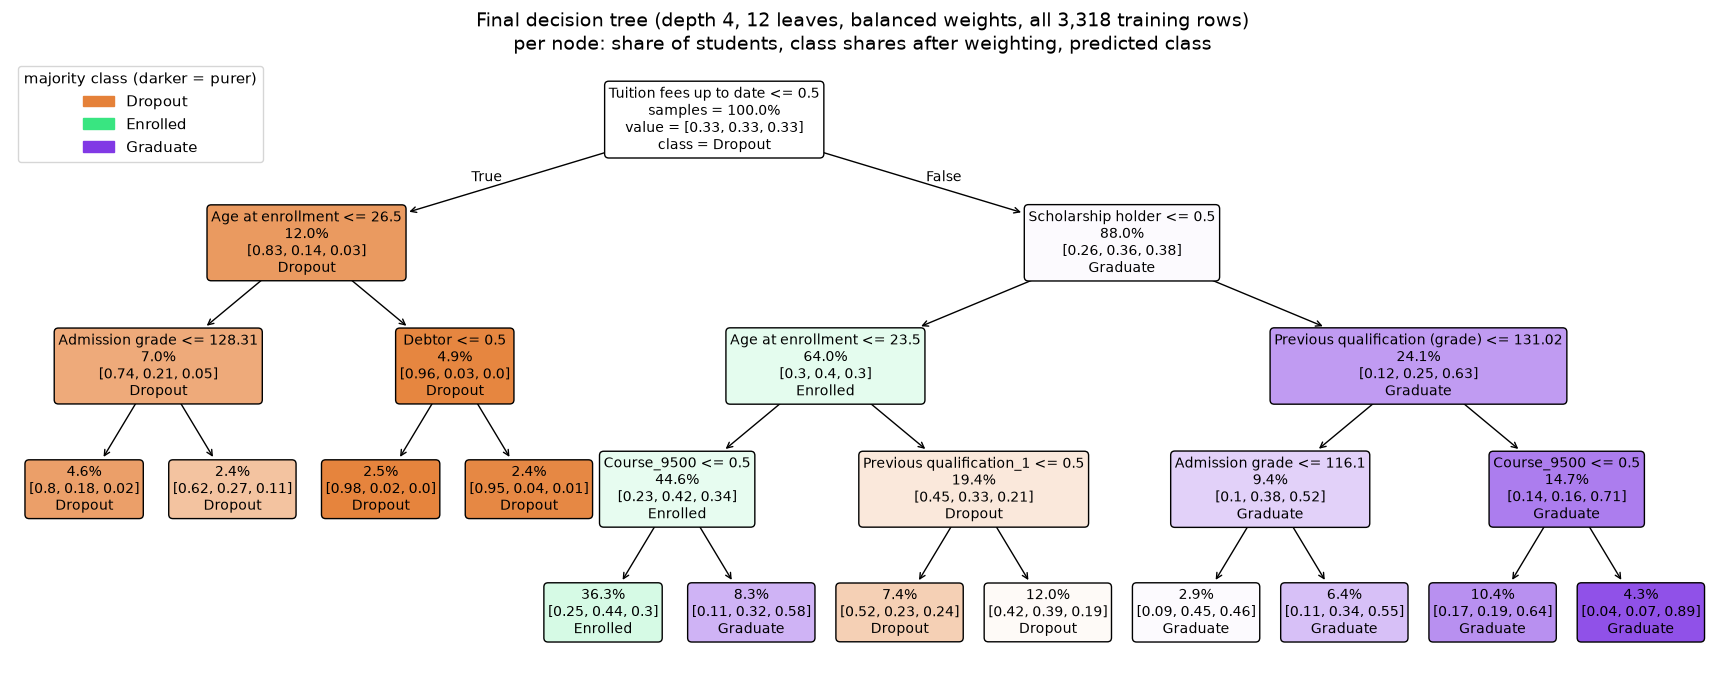

Target,students,Dropout,Enrolled,Graduate,predicted
"rule (Course_9500 is Nursing, Previous qualification_1 is secondary school)",,,,,
Tuition fees up to date = 0 & Age at enrollment <= 26.5 & Admission grade <= 128.3,153,0.856,0.105,0.039,Dropout
Tuition fees up to date = 0 & Age at enrollment <= 26.5 & Admission grade > 128.3,80,0.662,0.163,0.175,Dropout
Tuition fees up to date = 0 & Age at enrollment > 26.5 & Debtor = 0,84,0.988,0.012,0.000,Dropout
Tuition fees up to date = 0 & Age at enrollment > 26.5 & Debtor = 1,80,0.963,0.025,0.013,Dropout
Tuition fees up to date = 1 & Scholarship holder = 0 & Age at enrollment <= 23.5 & Course_9500 = 0,1204,0.262,0.256,0.482,Enrolled
Tuition fees up to date = 1 & Scholarship holder = 0 & Age at enrollment <= 23.5 & Course_9500 = 1,275,0.091,0.149,0.760,Graduate
Tuition fees up to date = 1 & Scholarship holder = 0 & Age at enrollment > 23.5 & Previous qualification_1 = 0,246,0.508,0.126,0.366,Dropout
Tuition fees up to date = 1 & Scholarship holder = 0 & Age at enrollment > 23.5 & Previous qualification_1 = 1,397,0.446,0.234,0.320,Dropout
Tuition fees up to date = 1 & Scholarship holder = 1 & Previous qualification (grade) <= 131.0 & Admission grade <= 116.1,97,0.082,0.237,0.680,Graduate


,mean,sd
Tuition fees up to date,0.058,0.009
Age at enrollment,0.049,0.009
Scholarship holder,0.038,0.007
Course,0.028,0.005
Gender,0.001,0.003
Previous qualification (grade),0.001,0.007
Marital status,0.000,0.000
Application mode,0.000,0.000


root split over 20 bootstrap refits: {'Tuition fees up to date': 20}
columns in the top 3 by impurity importance, out of 20 refits: {'Scholarship holder': 20, 'Tuition fees up to date': 20, 'Age at enrollment': 18, "Mother's occupation": 1, "Mother's qualification": 1}
distinct top-3 sets: 3


In [9]:
# Q2.3: the submitted tree drawn in full, which columns the holdout score depends on, and how stable the splits are.
from matplotlib.patches import Patch
from sklearn.tree._export import _color_brew   # the colours plot_tree gives each class, for the legend

feature_names = dt_final[:-1].get_feature_names_out()
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(dt_final[-1], feature_names=feature_names, class_names=dt_final.classes_, filled=True, impurity=False,
          proportion=True, rounded=True, precision=2, label="root", fontsize=10, ax=ax)
ax.legend(handles=[Patch(color=np.array(c) / 255, label=k) for c, k in zip(_color_brew(3), dt_final.classes_)],
          title="majority class (darker = purer)", loc="upper left", fontsize=11)
ax.set_title(f"Final decision tree (depth {dt_final[-1].get_depth()}, {dt_final[-1].get_n_leaves()} leaves, "
             "balanced weights, all 3,318 training rows)\nper node: share of students, class shares after weighting, predicted class",
             fontsize=14)
plt.show()


def leaf_rules(fitted_tree, names):
    """The conditions on the path to each leaf, with 0/1 columns written as '= 0' or '= 1'."""
    t, rules = fitted_tree.tree_, {}

    def walk(node, conds):
        if t.children_left[node] == -1:
            rules[node] = " & ".join(conds)
            return
        name, thr = names[t.feature[node]], t.threshold[node]
        binary = thr == 0.5 and (name in BINARY or any(name.startswith(c + "_") for c in NOMINAL))
        walk(t.children_left[node], conds + [f"{name} = 0" if binary else f"{name} <= {thr:.1f}"])
        walk(t.children_right[node], conds + [f"{name} = 1" if binary else f"{name} > {thr:.1f}"])

    walk(0, [])
    return rules


# Every leaf of the final tree: its rule, how many training students reach it, and their actual (unweighted) outcomes.
leaf_id = dt_final[-1].apply(dt_final[:-1].transform(X_train))
leaf_table = pd.crosstab(leaf_id, y_train, normalize="index")[CLASSES]
leaf_table.insert(0, "students", pd.Series(leaf_id).value_counts())
leaf_table["predicted"] = dt_final[-1].classes_[dt_final[-1].tree_.value[leaf_table.index, 0].argmax(axis=1)]
leaf_table.index = [leaf_rules(dt_final[-1], feature_names)[i] for i in leaf_table.index]
with pd.option_context("display.max_colwidth", 200):
    display(leaf_table.rename_axis("rule (Course_9500 is Nursing, Previous qualification_1 is secondary school)"))


def original_column(name):
    """Map a one-hot column such as 'Course_9500' back to the column it came from."""
    return next((c for c in NOMINAL if name.startswith(c + "_")), name)


# Permutation importance on the holdout, for the tree fit on the development rows (the full refit has seen the holdout).
perm_tree = permutation_importance(dt_dev, X_hold, y_hold, scoring="f1_macro", n_repeats=20, random_state=SEED)
perm_tree = pd.DataFrame({"mean": perm_tree.importances_mean, "sd": perm_tree.importances_std},
                         index=X_hold.columns).drop(index="International").sort_values("mean", ascending=False)
display(perm_tree.head(8).round(3))

# Refit the chosen settings on 20 bootstrap samples of the training rows.
rng = np.random.default_rng(SEED)
roots, top3 = [], []
for b in range(20):
    rows = rng.integers(0, len(X_train), len(X_train))
    boot = clone(dt_final).fit(X_train.iloc[rows], y_train.iloc[rows])
    names = boot[:-1].get_feature_names_out()
    roots.append(original_column(names[boot[-1].tree_.feature[0]]))
    imp = pd.Series(boot[-1].feature_importances_, index=[original_column(n) for n in names]).groupby(level=0).sum()
    top3.append(tuple(sorted(imp.nlargest(3).index)))
print("root split over 20 bootstrap refits:", pd.Series(roots).value_counts().to_dict())
print("columns in the top 3 by impurity importance, out of 20 refits:",
      pd.Series([c for t in top3 for c in t]).value_counts().to_dict())
print("distinct top-3 sets:", len(set(top3)))

**Written response: Q2.3**

- Tuition comes first. All four leaves for the 397 students behind on fees predict Dropout, and between 0.662 and 0.988 of the students in them actually dropped out (the most for those older than 26.5). Paid-up scholarship holders land in Graduate leaves, where 0.680 to 0.944 graduated, the most for Nursing students with a previous grade above 131.0. Paid-up students without a scholarship split on age. Those over 23.5 go to Dropout leaves (0.446 and 0.508 dropped out), and younger Nursing students go to a Graduate leaf (0.760).
- The top of the tree is stable. Tuition was the root split in all 20 bootstrap refits, and tuition and scholarship were among the top three columns in all 20 (age in 18). Permutation importance on the holdout agrees: tuition 0.058, age 0.049, scholarship 0.038, course 0.028, and nothing else above 0.001.
- The Enrolled reading doesn't hold up. The only Enrolled leaf holds 1,204 young, paid-up students without a scholarship, but just 0.256 of them were Enrolled and 0.482 graduated. Balancing alone puts the label there, and no leaf has Enrolled as its most common outcome (holdout Enrolled precision 0.226). The lower splits rest on leaves of 80 to 97 students. And all of it is association. Falling behind on fees probably signals money trouble that also drives dropout, so the tree can't tell us that enforcing payment would keep students enrolled.

## Q2.4. Submit your tree's predictions to Kaggle

**5 points**

Write your final tree's predictions for `X_test` with `write_submission(predictions, "dt")`, and upload `submissions/submission_dt.csv` to the [Decision Tree competition](https://www.kaggle.com/t/e50d66fd164642fd98f915f0b89970d3). The link is an invitation: open it while signed in to Kaggle to join. In the written response, give your Kaggle team name and public leaderboard score.

In [10]:
# Q2.4: the final tree (refit on all training rows in Q2.2) predicts the 1,106 test students.
write_submission(dt_final.predict(X_test), "dt")

wrote submissions/submission_dt.csv: 1106 rows, {'Enrolled': 407, 'Dropout': 354, 'Graduate': 345}


In [11]:
grader.check("q2_4")

q2_4 results: All test cases passed!

**Written response: Q2.4**

- Kaggle team name: **Tang J. Wang**
- Public leaderboard score (macro-F1): **0.51143**

# Part 3. Model 2: an ensemble of your choice

Your second model is an ensemble of your choice: any ensemble method taught in lecture, implemented with scikit-learn. You must be able to explain how it works. The Kaggle Rules page states the rule in full.

## Q3.1. Prepare the data

**5 points**

Prepare the data for your ensemble. Reusing your Q2.1 preprocessing is fine if it suits this model. In the written response, explain each preprocessing decision and why it suits the ensemble you chose.

In [12]:
# Q3.1: one preparation per ensemble family. The forest reuses the tree's; boosting reads the codes as categories itself.
forest_prep = one_hot   # same columns as the tree: International dropped, codes one-hot with rare codes pooled
boost_prep = make_column_transformer(("passthrough", KEPT), verbose_feature_names_out=False).set_output(transform="pandas")
boost_probe = HistGradientBoostingClassifier(categorical_features=NOMINAL, random_state=SEED).fit(boost_prep.fit_transform(X_dev), y_dev)
print(f"forest input: {forest_prep.fit(X_dev).transform(X_dev).shape[1]} columns; boosting input: "
      f"{boost_prep.transform(X_dev).shape[1]} columns, {int(boost_probe.is_categorical_.sum())} of them read as categories")
print("most levels in one categorical column:", X_train[NOMINAL].nunique().max(), "(boosting allows up to 255)")

forest input: 90 columns; boosting input: 20 columns, 9 of them read as categories
most levels in one categorical column: 41 (boosting allows up to 255)


**Written response: Q3.1**

- Our ensemble is gradient boosting (HistGradientBoostingClassifier), on the raw columns minus International. It treats the 9 code columns as categories, so a split can send any group of codes one way ("Nursing or Social Service") instead of thresholding arbitrary numbers, and one-hot isn't needed. Our largest code column has 41 levels, under its limit of 255. An unseen code counts as missing, and since training had no missing values, it goes to whichever side of a split held more training students.
- The rest follows the tree. International is dropped as a copy of Nationality. Nothing is scaled, because boosting also splits on thresholds (after binning each numeric column into at most 255 quantile bins). Nothing is imputed. The random forest we compared in Q3.2 reuses the Q2.1 one-hot pipeline (90 columns), since it is built from the same kind of tree.

## Q3.2. Choose, justify and tune your ensemble

**8 points**

Select your final ensemble. In the written response, explain which ensemble you chose, how it makes a prediction, and why you expected it to improve on your tree; then what you tuned, how you estimated performance on students the model has not seen, and the evidence that led to your final choice.

In [13]:
# Q3.2: a random forest and gradient boosting, tuned on the same five folds as the tree.
ens_pipe = Pipeline([("prep", forest_prep), ("model", RandomForestClassifier())])
ens_grid = [
    {"prep": [forest_prep],
     "model": [RandomForestClassifier(n_estimators=500, criterion="gini", n_jobs=1, random_state=SEED)],
     "model__max_features": [3, 6, 9, 45],   # of the 90 one-hot columns; 6 is log2, 9 is sqrt, 45 is half
     "model__min_samples_leaf": [3, 5, 10, 20],
     "model__class_weight": [None, "balanced_subsample"]},
    {"prep": [boost_prep],
     "model": [HistGradientBoostingClassifier(learning_rate=0.05, min_samples_leaf=20, categorical_features=NOMINAL,
                                              random_state=SEED)],
     "model__max_iter": [25, 50, 100, 200, 400],
     "model__max_leaf_nodes": [7, 15, 31],
     "model__class_weight": [None, "balanced"]},
]


def ens_table(cv_results):
    res = pd.DataFrame(cv_results)
    res["family"] = [type(p["model"]).__name__ for p in res["params"]]
    res["weights"] = ["balanced" if p.get("model__class_weight") else "none" for p in res["params"]]
    res["settings"] = [", ".join(f"{k.split('__')[1]}={v}" for k, v in p.items() if k.startswith("model__"))
                       for p in res["params"]]
    return res


def pick_ensemble(cv_results):
    """Best mean overall, but boosting if the two families' best means are within one SE (decided before the search)."""
    res = ens_table(cv_results)
    best = res.loc[res.groupby("family")["mean_test_score"].idxmax()].set_index("family")
    top = best["mean_test_score"].idxmax()
    se = best.loc[top, "std_test_score"] / np.sqrt(cv.get_n_splits())
    winner = top if best["mean_test_score"].max() - best["mean_test_score"].min() > se else "HistGradientBoostingClassifier"
    return res.index[(res["family"] == winner) & (res["mean_test_score"] == best.loc[winner, "mean_test_score"])][0]


ens_search = GridSearchCV(ens_pipe, ens_grid, scoring="f1_macro", cv=cv, refit=pick_ensemble, n_jobs=-1).fit(X_dev, y_dev)
ens_res = ens_table(ens_search.cv_results_)
cols = ["family", "settings", "mean_test_score", "std_test_score"]
for fam in ["RandomForestClassifier", "HistGradientBoostingClassifier"]:
    display(ens_res[ens_res["family"] == fam].sort_values("mean_test_score", ascending=False)[cols].head(5))
display(ens_res.pivot_table(index="family", columns="weights", values="mean_test_score", aggfunc="max")
        .rename(columns=lambda w: f"best CV macro-F1, class weights {w}"))
chosen_ens = ens_res.loc[ens_search.best_index_]
print(f"chosen: {chosen_ens['family']} ({chosen_ens['settings']}), CV macro-F1 {chosen_ens['mean_test_score']:.3f} "
      f"(fold SD {chosen_ens['std_test_score']:.3f})")

# Fold-by-fold against the tree: the same five folds, so the differences are paired.
fold_cols = [f"split{i}_test_score" for i in range(5)]
paired = pd.DataFrame({"tree": tree_res.loc[tree_search.best_index_, fold_cols].to_numpy(float),
                       "ensemble": ens_res.loc[ens_search.best_index_, fold_cols].to_numpy(float)},
                      index=[f"fold {i + 1}" for i in range(5)])
paired["ensemble - tree"] = paired["ensemble"] - paired["tree"]
display(paired.round(3))

# The estimate for unseen students: the chosen ensemble, fit on the development rows, on the holdout.
ens_dev = ens_search.best_estimator_
ens_hold_pred = ens_dev.predict(X_hold)
print(f"holdout macro-F1 {f1_score(y_hold, ens_hold_pred, average='macro'):.3f}")
print(classification_report(y_hold, ens_hold_pred, digits=3))

# The ensemble we submit: the same settings, refit on all 3,318 training rows.
ens_final = clone(ens_dev).fit(X_train, y_train)

,family,settings,mean_test_score,std_test_score
24,RandomForestClassifier,"class_weight=balanced_subsample, max_features=9, min_samples_leaf=3",0.570,0.007
21,RandomForestClassifier,"class_weight=balanced_subsample, max_features=6, min_samples_leaf=5",0.567,0.012
26,RandomForestClassifier,"class_weight=balanced_subsample, max_features=9, min_samples_leaf=10",0.565,0.011
16,RandomForestClassifier,"class_weight=balanced_subsample, max_features=3, min_samples_leaf=3",0.564,0.012
22,RandomForestClassifier,"class_weight=balanced_subsample, max_features=6, min_samples_leaf=10",0.562,0.016


,family,settings,mean_test_score,std_test_score
51,HistGradientBoostingClassifier,"class_weight=balanced, max_iter=50, max_leaf_nodes=15",0.569,0.019
50,HistGradientBoostingClassifier,"class_weight=balanced, max_iter=50, max_leaf_nodes=7",0.569,0.021
54,HistGradientBoostingClassifier,"class_weight=balanced, max_iter=100, max_leaf_nodes=15",0.568,0.020
48,HistGradientBoostingClassifier,"class_weight=balanced, max_iter=25, max_leaf_nodes=15",0.566,0.021
47,HistGradientBoostingClassifier,"class_weight=balanced, max_iter=25, max_leaf_nodes=7",0.563,0.016


weights,"best CV macro-F1, class weights balanced","best CV macro-F1, class weights none"
family,,
HistGradientBoostingClassifier,0.569,0.553
RandomForestClassifier,0.570,0.509


chosen: HistGradientBoostingClassifier (class_weight=balanced, max_iter=50, max_leaf_nodes=15), CV macro-F1 0.569 (fold SD 0.019)


,tree,ensemble,ensemble - tree
fold 1,0.520,0.565,0.045
fold 2,0.550,0.600,0.050
fold 3,0.514,0.553,0.040
fold 4,0.522,0.547,0.026
fold 5,0.514,0.579,0.065


holdout macro-F1 0.570
              precision    recall  f1-score   support

     Dropout      0.663     0.563     0.609       213
    Enrolled      0.320     0.462     0.378       119
    Graduate      0.746     0.699     0.722       332

    accuracy                          0.613       664
   macro avg      0.576     0.575     0.570       664
weighted avg      0.643     0.613     0.624       664



**Written response: Q3.2**

- We chose gradient boosting, from the course's boosting lecture (ensemble methods, after bagging and random forests). Ours runs 50 rounds of small trees, each with at most 15 leaves. Each round fits one tree per class to the gradient of the log-loss (how far the current predicted probabilities are from the truth) and adds it with a learning rate of 0.05. To predict, it sums each class's tree outputs, applies a softmax, and takes the largest. Balanced weights make errors on Enrolled students cost more.
- Our tree is limited by bias. It scores 0.532 on its training folds and 0.524 on validation, and deeper trees just memorize (1.000 vs 0.467 with leaves of 1). Boosting adds many small trees, each correcting the earlier ones, so it can fit more structure without any single tree memorizing. That is why we expected it to help. The alternative was a random forest, which averages deep trees to cut variance.
- On the tree's five folds we tuned the forest's columns per split (3, 6, 9, 45), leaf size (3 to 20) and weights, and boosting's rounds (25 to 400), leaves (7, 15, 31) and weights. The best forest scored 0.570 (9 columns, leaf 3) and the best boosting model 0.569 (50 rounds, 15 leaves, balanced). That is within one SE, so our tie rule, fixed before the search, picked boosting, the safer of the two for the autograder's exact reproduction check. When we re-ran the notebook on Linux, the forest's CV scores moved in the third decimal while boosting's did not change. Boosting's optimum is inside its grid (0.566 at 25 rounds and 0.568 at 100), and weights helped both families (best unweighted 0.553 and 0.509). Boosting beat the tree on all five folds (by 0.026 to 0.065) and on the holdout (0.570 vs 0.480).

## Q3.3. Interpret your ensemble

**7 points**

Interpret your final ensemble. In the written response, explain what it tells you about which students drop out, remain enrolled, or graduate, and how much you trust that reading.

,ensemble,ensemble sd,tree,tree sd
Course,0.060,0.012,0.028,0.005
Tuition fees up to date,0.049,0.009,0.058,0.009
Scholarship holder,0.028,0.009,0.038,0.007
Application mode,0.026,0.008,0.000,0.000
Mother's occupation,0.020,0.008,0.000,0.000
Age at enrollment,0.017,0.008,0.049,0.009
Previous qualification (grade),0.015,0.007,0.001,0.007
Father's occupation,0.014,0.008,0.000,0.000
Mother's qualification,0.011,0.007,0.000,0.000
Admission grade,0.009,0.007,0.000,0.000


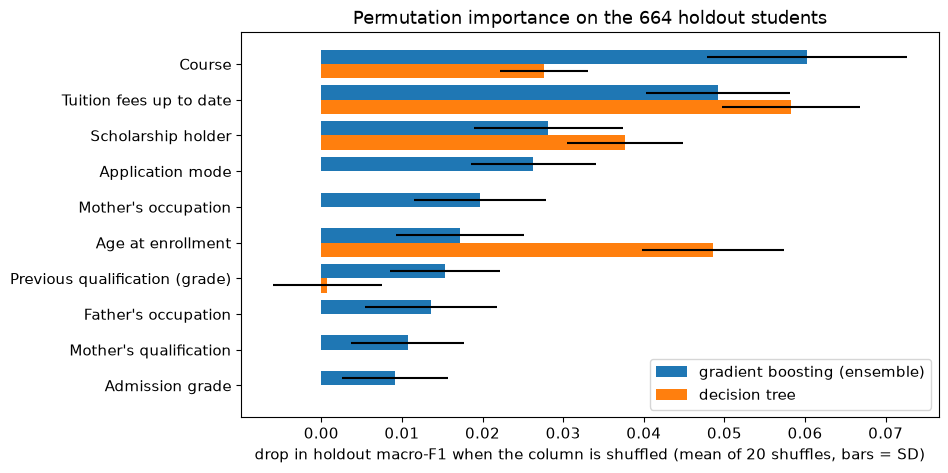

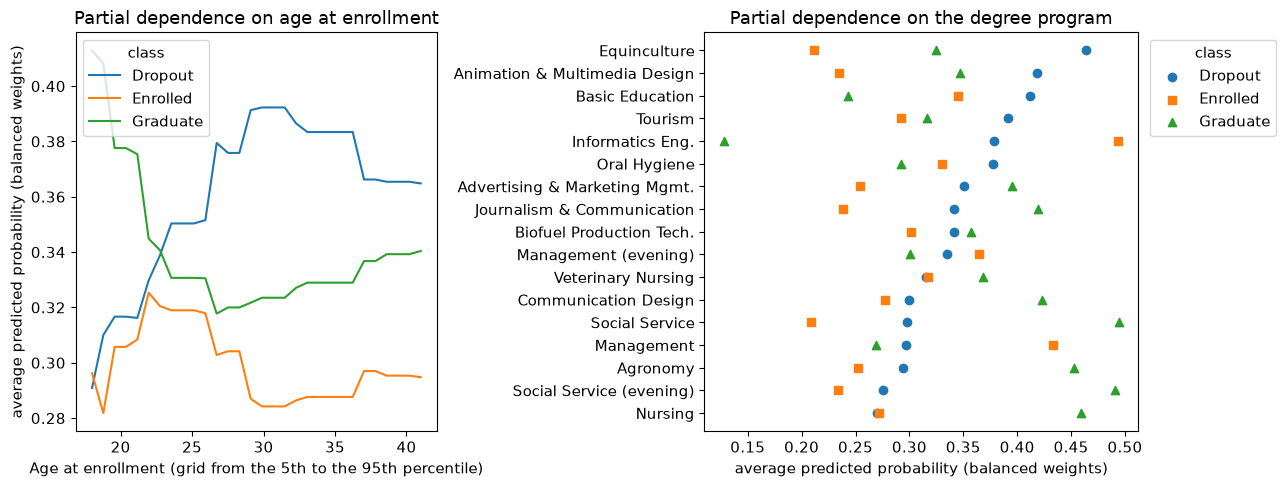

age 18 to 41: P(Dropout) 0.29 to 0.36, P(Enrolled) 0.30 to 0.29, P(Graduate) 0.41 to 0.34


,Dropout,Enrolled,Graduate
Nursing,0.270,0.271,0.459
Social Service (evening),0.275,0.234,0.491
Agronomy,0.294,0.253,0.453
Management,0.297,0.434,0.269
Social Service,0.297,0.208,0.494
Communication Design,0.300,0.278,0.423
Veterinary Nursing,0.315,0.317,0.368
Management (evening),0.335,0.365,0.300
Biofuel Production Tech.,0.341,0.302,0.357
Journalism & Communication,0.342,0.239,0.420


In [14]:
# Q3.3: which columns the ensemble's holdout score depends on (next to the tree's), and how two of them move each class.
perm_ens = permutation_importance(ens_dev, X_hold, y_hold, scoring="f1_macro", n_repeats=20, random_state=SEED)
perm_ens = pd.DataFrame({"mean": perm_ens.importances_mean, "sd": perm_ens.importances_std},
                        index=X_hold.columns).drop(index="International")
perm_both = pd.DataFrame({"ensemble": perm_ens["mean"], "ensemble sd": perm_ens["sd"],
                          "tree": perm_tree["mean"], "tree sd": perm_tree["sd"]}).sort_values("ensemble", ascending=False)
display(perm_both.head(10).round(3))

top = perm_both.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))
ax.barh(y + 0.2, top["ensemble"], height=0.4, xerr=top["ensemble sd"], label="gradient boosting (ensemble)")
ax.barh(y - 0.2, top["tree"], height=0.4, xerr=top["tree sd"], label="decision tree")
ax.set_yticks(y, top.index)
ax.set(xlabel="drop in holdout macro-F1 when the column is shuffled (mean of 20 shuffles, bars = SD)",
       title="Permutation importance on the 664 holdout students")
ax.legend(loc="lower right")
plt.show()

# Partial dependence: the average predicted probability of each class as one column varies, the others as observed.
COURSE_NAMES = {33: "Biofuel Production Tech.", 171: "Animation & Multimedia Design", 8014: "Social Service (evening)",
                9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing", 9119: "Informatics Eng.",
                9130: "Equinculture", 9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
                9556: "Oral Hygiene", 9670: "Advertising & Marketing Mgmt.", 9773: "Journalism & Communication",
                9853: "Basic Education", 9991: "Management (evening)"}
pd_age = partial_dependence(ens_dev, X_dev.astype({"Age at enrollment": float}), ["Age at enrollment"], grid_resolution=30)
pd_course = partial_dependence(ens_dev, X_dev, ["Course"], categorical_features=["Course"])
course_pd = pd.DataFrame(pd_course["average"].T, columns=ens_dev.classes_,
                         index=[COURSE_NAMES[c] for c in pd_course["grid_values"][0]]).sort_values("Dropout")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.2]})
for k, cls in enumerate(ens_dev.classes_):
    axes[0].plot(pd_age["grid_values"][0], pd_age["average"][k], label=cls)
axes[0].set(xlabel="Age at enrollment (grid from the 5th to the 95th percentile)",
            ylabel="average predicted probability (balanced weights)", title="Partial dependence on age at enrollment")
axes[0].legend(title="class")
yy = np.arange(len(course_pd))
for cls, marker in [("Dropout", "o"), ("Enrolled", "s"), ("Graduate", "^")]:
    axes[1].scatter(course_pd[cls], yy, marker=marker, label=cls)
axes[1].set_yticks(yy, course_pd.index)
axes[1].set(xlabel="average predicted probability (balanced weights)", title="Partial dependence on the degree program")
axes[1].legend(title="class", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()
g, avg = pd_age["grid_values"][0], pd_age["average"]
print(f"age {g[0]:.0f} to {g[-1]:.0f}: P(Dropout) {avg[0][0]:.2f} to {avg[0][-1]:.2f}, "
      f"P(Enrolled) {avg[1][0]:.2f} to {avg[1][-1]:.2f}, P(Graduate) {avg[2][0]:.2f} to {avg[2][-1]:.2f}")
display(course_pd)

**Written response: Q3.3**

- On the holdout, permutation importance ranks the program first (0.060), then tuition (0.049), scholarship (0.028), application mode (0.026) and mother's occupation (0.020). By partial dependence, the average P(Dropout) ranges from 0.270 for Nursing to 0.464 for Equinculture. Informatics Engineering has P(Enrolled) 0.493 but P(Graduate) 0.128, which looks like students who finish late rather than quit. Moving age from 18 to 41 raises P(Dropout) from 0.29 to 0.36 and lowers P(Graduate) from 0.41 to 0.34.
- Tuition and scholarship rank high in both models, so we trust those most. On age the models disagree (0.049 for the tree, 0.017 here), but that doesn't mean age matters less. The ensemble can also get age from application mode (39 means over 23) and similar columns, so shuffling age alone costs it little.
- Below the top few, the order isn't reliable. Every column from previous qualification grade down scores 0.015 or less, with SDs of 0.007 to 0.008. The partial dependence curves average balanced-weight predictions, so they overstate Enrolled, and they mix values that rarely occur together, like a 41-year-old with a school leaver's profile. As with the tree, these are associations measured on 664 students, not effects of changing anything.

## Q3.4. Submit your ensemble's predictions to Kaggle

**5 points**

Write your final ensemble's predictions for `X_test` with `write_submission(predictions, "ensemble")`, and upload `submissions/submission_ensemble.csv` to the [Ensemble competition](https://www.kaggle.com/t/49d8d5280406448a80a62786912c4595). The link is an invitation: open it while signed in to Kaggle to join. In the written response, give your Kaggle team name and public leaderboard score.

In [15]:
# Q3.4: the final ensemble (refit on all training rows in Q3.2) predicts the 1,106 test students.
write_submission(ens_final.predict(X_test), "ensemble")

wrote submissions/submission_ensemble.csv: 1106 rows, {'Graduate': 492, 'Dropout': 311, 'Enrolled': 303}


In [16]:
grader.check("q3_4")

q3_4 results: All test cases passed!

**Written response: Q3.4**

- Kaggle team name: **Tang J. Wang**
- Public leaderboard score (macro-F1): **0.57132**

# Part 4. Comparing your models

## Q4.1. Compare your models and make a recommendation

**12 points**

Compare your two models and recommend one. In the written response, make the case for your recommendation with evidence from your own output, and discuss whether and how a university should act on its predictions.

,holdout macro-F1,F1 Dropout,F1 Enrolled,F1 Graduate,accuracy,CV macro-F1 (dev folds)
decision tree,0.480,0.556,0.329,0.554,0.480,0.524
gradient boosting,0.570,0.609,0.378,0.722,0.613,0.569


bootstrap SE of holdout macro-F1: tree 0.019, ensemble 0.020
ensemble minus tree, holdout macro-F1: 0.090; 95% bootstrap interval [0.055, 0.128]; share of resamples with the ensemble ahead 1.000
on the five CV folds the ensemble was ahead in 5 of 5, by 0.026 to 0.065


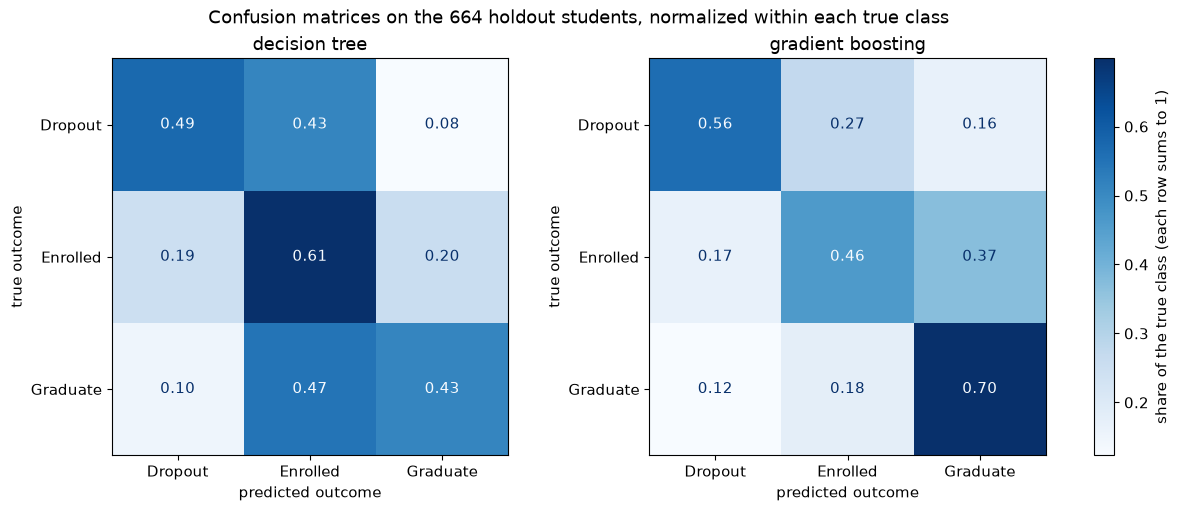

,students,actual dropouts,flagged as Dropout,Dropout recall,Dropout precision
group,,,,,
Gender: female,2154,543,456,0.534,0.636
Gender: male,1164,523,511,0.654,0.669
Scholarship holder: no,2483,964,911,0.623,0.660
Scholarship holder: yes,835,102,56,0.304,0.554
Age at enrollment: 17-19,1477,300,197,0.363,0.553
Age at enrollment: 20-24,991,296,232,0.503,0.642
Age at enrollment: 25+,850,470,538,0.796,0.695


In [17]:
# Q4.1: both models on the same holdout students, with the uncertainty of the gap, and where each one errs.
models = {"decision tree": dt_hold_pred, "gradient boosting": ens_hold_pred}
summary = {}
for name, pred in models.items():
    f1s = f1_score(y_hold, pred, average=None, labels=CLASSES)
    summary[name] = {"holdout macro-F1": f1_score(y_hold, pred, average="macro"),
                     **{f"F1 {c}": v for c, v in zip(CLASSES, f1s)},
                     "accuracy": np.mean(pred == y_hold)}
summary["decision tree"]["CV macro-F1 (dev folds)"] = tree_res.loc[tree_search.best_index_, "mean_test_score"]
summary["gradient boosting"]["CV macro-F1 (dev folds)"] = ens_res.loc[ens_search.best_index_, "mean_test_score"]
display(pd.DataFrame(summary).T.round(3))

# Paired bootstrap: resample the 664 holdout students and recompute both macro-F1s on the same resample.
rng = np.random.default_rng(SEED)
truth, p_tree, p_ens = y_hold.to_numpy(), dt_hold_pred, ens_hold_pred
boot = []
for _ in range(2000):
    i = rng.integers(0, len(truth), len(truth))
    boot.append((f1_score(truth[i], p_tree[i], average="macro"), f1_score(truth[i], p_ens[i], average="macro")))
boot = np.array(boot)
gaps = boot[:, 1] - boot[:, 0]
print(f"bootstrap SE of holdout macro-F1: tree {boot[:, 0].std():.3f}, ensemble {boot[:, 1].std():.3f}")
print(f"ensemble minus tree, holdout macro-F1: {f1_score(truth, p_ens, average='macro') - f1_score(truth, p_tree, average='macro'):.3f}; "
      f"95% bootstrap interval [{np.quantile(gaps, 0.025):.3f}, {np.quantile(gaps, 0.975):.3f}]; "
      f"share of resamples with the ensemble ahead {np.mean(gaps > 0):.3f}")
print(f"on the five CV folds the ensemble was ahead in {int((paired['ensemble - tree'] > 0).sum())} of 5, "
      f"by {paired['ensemble - tree'].min():.3f} to {paired['ensemble - tree'].max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, (name, pred) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_hold, pred, labels=CLASSES, normalize="true", values_format=".2f",
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set(title=name, xlabel="predicted outcome", ylabel="true outcome")
fig.colorbar(axes[1].images[0], ax=axes, label="share of the true class (each row sums to 1)")
fig.suptitle("Confusion matrices on the 664 holdout students, normalized within each true class")
plt.show()

# Dropout recall and precision by group, from out-of-fold predictions of the recommended model on all 3,318 rows.
oof = pd.Series(cross_val_predict(clone(ens_dev), X_train, y_train, cv=cv), index=X_train.index)
groups = {"Gender": X_train["Gender"].map({0: "female", 1: "male"}),
          "Scholarship holder": X_train["Scholarship holder"].map({0: "no", 1: "yes"}),
          "Age at enrollment": pd.cut(X_train["Age at enrollment"], [0, 19, 24, 100], labels=["17-19", "20-24", "25+"]).astype(str)}
rows = []
for gname, g in groups.items():
    for level in sorted(g.unique()):
        m = g == level
        is_drop, flagged = y_train[m] == "Dropout", oof[m] == "Dropout"
        rows.append({"group": f"{gname}: {level}", "students": int(m.sum()), "actual dropouts": int(is_drop.sum()),
                     "flagged as Dropout": int(flagged.sum()),
                     "Dropout recall": (is_drop & flagged).sum() / is_drop.sum(),
                     "Dropout precision": (is_drop & flagged).sum() / max(flagged.sum(), 1)})
display(pd.DataFrame(rows).set_index("group").round(3))

**Written response: Q4.1**

- We recommend gradient boosting. On the same 664 holdout students it scores 0.570 macro-F1 vs 0.480 for the tree (bootstrap 95% interval for the gap [0.055, 0.128], ahead in every resample). It led on all five CV folds, and it scored 0.57132 vs 0.51143 on Kaggle's public leaderboard (about 22% of the test rows). It is better on every class (F1 for Dropout 0.609 vs 0.556, Enrolled 0.378 vs 0.329, Graduate 0.722 vs 0.554). The biggest gap is graduates: the tree calls 47% of them Enrolled, boosting 18%. The tree is still a good way to explain the main pattern, and the ensemble agrees with it on fees and scholarships.
- A university should use the model only as an early-warning list that leads to support (advising, tutoring, help with fees), never for admissions, penalties or debt collection. Boosting finds only 0.563 of the holdout dropouts, and about a third of the students it flags would not drop out (precision 0.663). Its Enrolled label is wrong more often than right (precision 0.320), so we wouldn't act on it. Only support that does little harm to a wrongly flagged student fits these error rates.
- The errors are uneven. Out of fold, it catches 0.796 of dropouts aged 25 or older but 0.363 of those aged 17 to 19, 0.654 of male vs 0.534 of female dropouts, and 0.304 of scholarship holders who drop out. A program built on it would miss most young dropouts and needs other ways to reach them. The strongest columns are about money, so the response should be financial help, not sanctions. The data cover students who entered one Portuguese polytechnic from 2008/09 to 2018/19 (per the paper in data/), so the model has to be rechecked and recalibrated on the university's own recent students first.

## Wrap-up

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fbe8ff; border-color: #eed4db; border-width: 1px; border-radius: 3px; padding: 10px;">

* How many hours did you spend on this assignment? Store an int or float in `hours_spent_on_hw`. If you worked in a pair, report the average per person.
* Briefly describe how you used AI assistance and how you checked its contributions.
* (Optional) Which aspect of the assignment did you find most challenging?

</div>

In [18]:
# Report your hours here. Replace None with an int or float.
hours_spent_on_hw = None

In [19]:
print("Notebook runtime, minutes:", round((time.time() - notebook_start) / 60, 1))

Notebook runtime, minutes: 1.6


**Written response: Wrap-up**

- We used Claude Code to write most of the code and a first draft of these answers. We checked its work by re-running the notebook from a restarted kernel, matching every number in the answers to the printed output, confirming that re-runs on a Mac and on a Linux machine like the autograder's write byte-identical submission files, and rewording the answers ourselves.
- The hardest part was getting an honest performance estimate while every choice was tuned on the same 3,318 rows. Keeping a holdout that no tuning step touched was our answer.